# Stage 02 - Prepare the 2022 existing generator fleet

This notebook converts the source-faithful existing-generation transcription into the normalized mainland Sistema Nacional Interconectado (SNI) fleet. It reconciles every row and MW to the source before writing the model-facing table.

The source workbook is retained locally as migration evidence, while the tracked CSV is the reproducible interface. Future plants, scenario assets, and nuclear placeholders are deliberately outside this baseline.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.artifacts import format_preflight_report, run_preflight
from src.environment import check_environment, format_environment_report

environment = check_environment()
if not environment.ok:
    raise RuntimeError(format_environment_report(environment))
preflight = run_preflight("02_generation", root=ROOT)
preflight.raise_for_errors()
print(format_environment_report(environment))
print(format_preflight_report(preflight))

Environment preflight: PASS
  environment: pypsa-earth-ec (expected pypsa-earth-ec)
  python: 3.11.14 (required >=3.10,<3.12)
  pypsa: 0.30.3 (>=0.25,<=0.30.3) [ok]
  numpy: 1.26.4 (<2) [ok]
  pandas: 2.3.3 (>=2) [ok]
  xarray: 2025.1.2 (>=2023.11.0,<=2025.1.2) [ok]
  h5netcdf: 1.7.3 (>=1) [ok]
  PyYAML: 6.0.3 (>=6) [ok]
  requests: 2.32.5 (>=2) [ok]
  jsonschema: 4.25.1 (>=4) [ok]
  nbformat: 5.10.4 (>=5) [ok]
  nbclient: 0.10.2 (>=0.10) [ok]
Artifact preflight: PASS (stage=02_generation)
  not-required planning_adjustment_totals_source: stage does not require this artifact
  not-required planning_adjustment_pdf: stage does not require this artifact
  not-required planning_older_demand_pdf: stage does not require this artifact
  not-required planning_older_generation_pdf: stage does not require this artifact
  not-required planning_older_transmission_pdf: stage does not require this artifact
  not-required planning_adjustment_generation_source: stage does not require this artifact
  n

## Sources, boundary, and identifiers

The plant inventory is the repository owner's transcription of Chapter 4, section 4.11.1, Annex 1 of the Electricity Master Plan. `source_row` preserves the original workbook row and is part of each stable plant identifier. The complete transcription contains both SNI and non-incorporated systems; only rows explicitly marked SNI enter this model.

Coordinates are evidence of varying strength: exact matches to the 2017 inventory, retained manual canton assignments, or same-province capacity proxies. The evidence table is one-to-one by `source_row`, preventing the duplicate-canton join that previously added four erroneous MW.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from src.generation import (
    assert_generation_acceptance,
    load_commissioning_events,
    load_generation_source,
    load_location_evidence,
    prepare_existing_generation,
)

source = load_generation_source(ROOT / "data/raw/generation/generation_existing_2022.csv")
locations = load_location_evidence(ROOT / "data/interim/generation/plant_location_evidence_2022.csv")
commissioning_events = load_commissioning_events(ROOT / "data/raw/generation/cenace_2022_commissioning_events.csv")
prepared = prepare_existing_generation(source, locations, commissioning_events)
assert_generation_acceptance(prepared)
prepared.carrier_summary

,carrier,plants,nominal_capacity_mw,effective_capacity_mw
0,biogas,2,8.32,7.20
1,biomass,3,144.30,136.40
2,hydro,65,5184.19,5144.61
3,oil,37,2061.88,1796.82
4,onwind,2,66.48,66.48
5,solar,24,24.48,23.60


## Capacity and carrier reconciliation

Nominal capacity is retained as `p_nom_mw`, matching the legacy network assembly convention. Effective capacity remains a separate source field for auditing. Three source rows legitimately report effective capacity slightly above nominal; those values are preserved rather than silently capped.

The model carriers preserve biomass and biogas separately at plant level, use `onwind` for wind, and retain the source's undifferentiated thermal plants as `oil`. Stage 06 aggregates these through the frozen statistical carrier mapping.

CENACE Table 3.1 provides 2022 operating dates for Sarapullo, Sabanilla, and the two Huascachaca unit groups. The earliest reported date is retained as the plant operating start for profile masking. Published event capacities remain separate because they do not exactly reconcile to the Master Plan plant capacities.

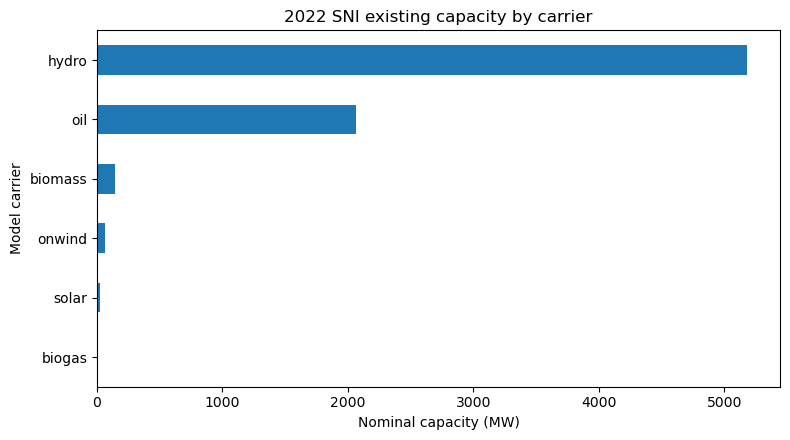

In [3]:
output_path = ROOT / "data/processed/generation/generators_2022.csv"
output_path.parent.mkdir(parents=True, exist_ok=True)
prepared.generators.to_csv(output_path, index=False)

figure_dir = ROOT / "reports/figures/phase_04"
figure_dir.mkdir(parents=True, exist_ok=True)
capacity = prepared.carrier_summary.sort_values("nominal_capacity_mw")
ax = capacity.plot.barh(x="carrier", y="nominal_capacity_mw", legend=False, figsize=(8, 4.5))
ax.set_xlabel("Nominal capacity (MW)")
ax.set_ylabel("Model carrier")
ax.set_title("2022 SNI existing capacity by carrier")
plt.tight_layout()
plt.savefig(figure_dir / "generation_capacity_by_carrier.png", dpi=160)
plt.show()

## Location evidence quality

Location methods are not equivalent observations. Exact 2017 matches are strongest; manual legacy mappings need individual source review; capacity proxies are low-confidence attachment aids. Phase 5 must retain this evidence when generators are attached to network buses.

In [4]:
prepared.location_summary

,location_method,plants,effective_capacity_mw
0,capacity_proxy_2017,17,1738.74
1,exact_2017,105,5064.09
2,manual_legacy,9,163.28
3,verified_mapped_location,2,209.00


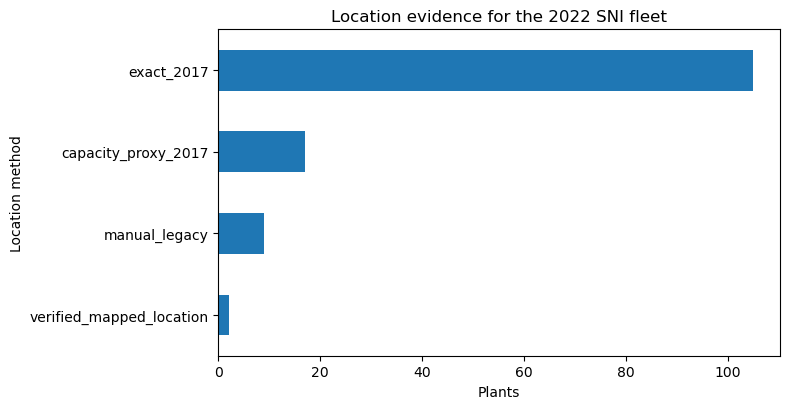

In [5]:
location = prepared.location_summary.sort_values("plants")
ax = location.plot.barh(x="location_method", y="plants", legend=False, figsize=(8, 4.2))
ax.set_xlabel("Plants")
ax.set_ylabel("Location method")
ax.set_title("Location evidence for the 2022 SNI fleet")
plt.tight_layout()
plt.savefig(figure_dir / "generation_location_evidence.png", dpi=160)
plt.show()

## Stage result

The output contains exactly 133 unique SNI plants and no future or hypothetical capacity. Commissioning and retirement years remain null because the retained source does not provide defensible row-level values. A later phase may enrich them only with traceable evidence.

In [6]:
summary = {
    "source_rows": len(source),
    "sni_plants": len(prepared.generators),
    "nominal_capacity_mw": float(prepared.generators["p_nom_mw"].sum()),
    "effective_capacity_mw": float(prepared.generators["effective_capacity_mw"].sum()),
    "duplicate_plant_ids": int(prepared.generators["plant_id"].duplicated().sum()),
    "missing_coordinates": int(prepared.generators[["latitude", "longitude"]].isna().any(axis=1).sum()),
    "in_year_commissioned_plants": int((prepared.generators["operating_start_basis"] == "cenace_2022_commissioning_event").sum()),
    "future_or_hypothetical_rows": int((prepared.generators["baseline_status"] != "existing_2022").sum()),
}
pd.Series(summary, name="value")

source_rows                     300.00
sni_plants                      133.00
nominal_capacity_mw            7489.65
effective_capacity_mw          7175.11
duplicate_plant_ids               0.00
missing_coordinates               0.00
in_year_commissioned_plants       3.00
future_or_hypothetical_rows       0.00
Name: value, dtype: float64